Code for missing values handling and graph work

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving clean dataset.xlsx to clean dataset.xlsx


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

file_name = "clean dataset.xlsx"

df_raw = pd.read_excel(file_name, sheet_name="Sheet1")

df = df_raw.copy()

print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 10 rows:")
display(df.head(10))

print("\nLast 5 rows:")
display(df.tail())


Dataset dimensions: (36, 16)

Column names:
['Years', 'Inflation', 'GDP Growth', 'Education', 'Unemployment Rate', 'GDP Per Capita', 'Real Interest Rate', 'Trade', 'Government Expense', 'Current Health expense', 'Gross fixed capital formation ', 'FDI', 'Poverty gap at $3.00 a day ', 'Poverty headcount ratio at $3.00 a day ', 'Life expectancy', 'Self employed Percentage']

Data types:
Years                                        int64
Inflation                                  float64
GDP Growth                                 float64
Education                                  float64
Unemployment Rate                           object
GDP Per Capita                             float64
Real Interest Rate                          object
Trade                                      float64
Government Expense                         float64
Current Health expense                      object
Gross fixed capital formation              float64
FDI                                        float64
P

,Years,Inflation,GDP Growth,Education,Unemployment Rate,GDP Per Capita,Real Interest Rate,Trade,Government Expense,Current Health expense,Gross fixed capital formation,FDI,Poverty gap at $3.00 a day,Poverty headcount ratio at $3.00 a day,Life expectancy,Self employed Percentage
0,1990,9.052132,4.458587,2.877300,..,344.455474,..,35.034576,2.51681,..,17.299750,0.612998,34.000000,79.500000,59.728,..
1,1991,11.791270,5.061568,2.419420,0.596,380.019843,..,35.419655,2.56676,..,17.348325,0.566384,30.066667,30.066667,59.864,67.079259
2,1992,9.509041,7.705898,1.961540,0.587,395.677209,..,37.694540,2.54968,..,18.589796,0.688314,26.133333,26.133333,59.983,66.863383
3,1993,9.973665,1.757748,1.999068,0.596,407.888141,..,38.499317,2.38643,..,19.112288,0.672760,22.200000,22.200000,60.083,66.537348
4,1994,12.368194,3.737416,2.036596,0.601,399.955928,..,35.057724,2.58931,..,17.833611,0.805119,18.266667,18.266667,60.197,66.391137
5,1995,12.343579,4.962609,2.074125,0.611,450.550279,..,36.132754,2.79531,..,17.034206,1.191752,14.333333,14.333333,60.273,66.309657
6,1996,10.373809,4.846581,2.111653,0.6,456.996962,..,38.330127,2.81057,..,17.377073,1.456054,10.400000,45.300000,60.466,66.309645
7,1997,11.375493,1.014396,2.149181,0.611,438.030943,..,36.852266,3.02230,..,16.342999,1.147229,12.100000,47.800000,60.623,64.003769
8,1998,6.228004,2.550234,2.186709,0.62,424.453698,..,34.011725,2.81689,..,15.044688,0.813610,13.800000,50.300000,61.134,65.191849
9,1999,4.142637,3.660133,2.224237,0.625,418.249257,..,32.319963,2.61148,..,13.931389,0.844795,14.300000,52.266667,61.540,65.192188



Last 5 rows:


,Years,Inflation,GDP Growth,Education,Unemployment Rate,GDP Per Capita,Real Interest Rate,Trade,Government Expense,Current Health expense,Gross fixed capital formation,FDI,Poverty gap at $3.00 a day,Poverty headcount ratio at $3.00 a day,Life expectancy,Self employed Percentage
31,2021,9.496416,6.513886,12.381001,6.338,1455.319224,-1.452259,27.030420,1.687461,2.990158,12.824692,0.616039,3.950000,19.750000,65.773000,57.77234
32,2022,19.873860,4.778107,10.505718,5.291,1538.322813,-0.356283,33.031353,1.973009,2.903548,13.850543,0.389981,4.366667,20.833333,67.417000,57.52826
33,2023,30.768128,-0.414936,10.477030,5.237,1360.324178,-0.904271,28.467693,1.946580,2.519883,12.258147,0.608281,4.783333,21.916667,67.649000,57.377534
34,2024,12.632532,3.081763,10.856413,5.492,1479.477552,-0.630277,27.565331,1.959795,2.711715,11.489253,0.716885,5.200000,23.000000,67.799000,57.215269
35,2025,3.545552,3.698427,10.666722,5.42,1595.909123,-0.767274,27.193537,1.953187,2.615799,12.572808,0.454694,4.991667,22.458333,67.649181,57.002473


In [ ]:

print("Shape:", df.shape)

print("\nActual missing cells (NaN):")
print(df.isna().sum())

print("\nText markers such as '..':")
print(
    df.astype("string")
      .apply(lambda col: col.str.strip().eq(".."))
      .sum()
)

print("\nDuplicate full rows:", df.duplicated().sum())
print("Duplicate years:", df["Years"].duplicated().sum())

print("\nYear range:",
      df["Years"].min(), "to", df["Years"].max())

print("\nNumeric summary:")
display(df.describe(include="all").T)


Shape: (36, 16)

Actual missing cells (NaN):
Years                                      0
Inflation                                  0
GDP Growth                                 0
Education                                  0
Unemployment Rate                          0
GDP Per Capita                             0
Real Interest Rate                         0
Trade                                      0
Government Expense                         0
Current Health expense                     0
Gross fixed capital formation              0
FDI                                        0
Poverty gap at $3.00 a day                 0
Poverty headcount ratio at $3.00 a day     0
Life expectancy                            0
Self employed Percentage                   0
dtype: int64

Text markers such as '..':
Years                                       0
Inflation                                   0
GDP Growth                                  0
Education                                   0
Unemployme

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Years,36.0,NaN,NaN,NaN,2007.5,10.535654,1990.0,1998.75,2007.5,2016.25,2025.0
Inflation,36.0,NaN,NaN,NaN,9.398617,5.65962,2.529328,4.900209,9.279872,11.822476,30.768128
GDP Growth,36.0,NaN,NaN,NaN,3.966934,2.06088,-1.274087,2.658792,4.167185,4.987349,7.831256
Education,36.0,NaN,NaN,NaN,5.84085,3.571298,1.96154,2.289912,4.91808,8.646301,12.381001
Unemployment Rate,36.0,33.0,0.611,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GDP Per Capita,36.0,NaN,NaN,NaN,943.822373,432.445697,344.455474,455.385291,975.546319,1365.360685,1595.909123
Real Interest Rate,36,23,..,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Trade,36.0,NaN,NaN,NaN,30.49439,4.656592,21.459964,26.951885,30.839078,34.096034,38.499317
Government Expense,36.0,NaN,NaN,NaN,2.206517,0.39765,1.44338,1.958143,2.20963,2.55395,3.0223
Current Health expense,36,27,..,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
actual_missing = df.isna().sum()

text_df = df.astype("string").apply(lambda col: col.str.strip())

missing_markers = text_df.isin(
    ["..", "...", "NA", "N/A", "null", "None", ""]
)

missing_report = pd.DataFrame({
    "Actual_NaN": actual_missing,
    "Text_Markers": missing_markers.sum(),
    "Total_Missing": actual_missing + missing_markers.sum()
})

missing_report["Missing_Percent"] = (
    missing_report["Total_Missing"] / len(df) * 100
).round(2)

display(missing_report.sort_values(
    "Total_Missing", ascending=False
))

print("Total cells:", df.size)
print("Total missing cells:",
      missing_report["Total_Missing"].sum())


,Actual_NaN,Text_Markers,Total_Missing,Missing_Percent
Real Interest Rate,0,14,14,38.89
Current Health expense,0,10,10,27.78
Self employed Percentage,0,1,1,2.78
Unemployment Rate,0,1,1,2.78
Education,0,0,0,0.00
GDP Growth,0,0,0,0.00
Years,0,0,0,0.00
Inflation,0,0,0,0.00
Trade,0,0,0,0.00
GDP Per Capita,0,0,0,0.00


Total cells: 576
Total missing cells: 26


In [ ]:

print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate years:", df["Years"].duplicated().sum())

expected_years = set(range(
    int(df["Years"].min()),
    int(df["Years"].max()) + 1
))

actual_years = set(df["Years"].dropna().astype(int))
missing_years = sorted(expected_years - actual_years)

print("Missing years:", missing_years)
print("Number of observations:", len(df))
print("Number of unique years:", df["Years"].nunique())


Exact duplicate rows: 0
Duplicate years: 0
Missing years: []
Number of observations: 36
Number of unique years: 36


In [ ]:

print("Data types before cleaning:")
print(df.dtypes)

object_cols = df.select_dtypes(include="object").columns

for col in object_cols:
    print(f"\n{col}")
    print("Examples:", df[col].drop_duplicates().head(10).tolist())


Data types before cleaning:
Years                                        int64
Inflation                                  float64
GDP Growth                                 float64
Education                                  float64
Unemployment Rate                           object
GDP Per Capita                             float64
Real Interest Rate                          object
Trade                                      float64
Government Expense                         float64
Current Health expense                      object
Gross fixed capital formation              float64
FDI                                        float64
Poverty gap at $3.00 a day                 float64
Poverty headcount ratio at $3.00 a day     float64
Life expectancy                            float64
Self employed Percentage                    object
dtype: object

Unemployment Rate
Examples: ['..', 0.596, 0.587, 0.601, 0.611, 0.6, 0.62, 0.625, 0.614, 0.615]

Real Interest Rate
Examples: ['..', 0.0057407

In [ ]:

numeric_df = df.copy()

for col in numeric_df.columns:
    numeric_df[col] = pd.to_numeric(
        numeric_df[col].replace(
            ["..", "...", "NA", "N/A", "null", "None", ""],
            np.nan
        ),
        errors="coerce"
    )

print("Minimum and maximum values:")
display(numeric_df.describe().T[["min", "max"]])


print("\nInflation above 20%:")
display(df.loc[df["Inflation"] > 20,
               ["Years", "Inflation", "GDP Growth"]])

print("\nNegative GDP growth:")
display(df.loc[df["GDP Growth"] < 0,
               ["Years", "GDP Growth", "Inflation"]])


Minimum and maximum values:


/tmp/ipykernel_1835/4228680010.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  numeric_df[col].replace(


,min,max
Years,1990.000000,2025.000000
Inflation,2.529328,30.768128
GDP Growth,-1.274087,7.831256
Education,1.961540,12.381001
Unemployment Rate,0.398000,6.338000
GDP Per Capita,344.455474,1595.909123
Real Interest Rate,-1.710998,7.761265
Trade,21.459964,38.499317
Government Expense,1.443380,3.022300
Current Health expense,2.036663,2.990158



Inflation above 20%:


,Years,Inflation,GDP Growth
18,2008,20.286121,2.120441
33,2023,30.768128,-0.414936



Negative GDP growth:


,Years,GDP Growth,Inflation
30,2020,-1.274087,9.740116
33,2023,-0.414936,30.768128


In [ ]:

print("Column names:")
for col in df.columns:
    print(repr(col))

print("\nText columns:")
text_cols = df.select_dtypes(
    include=["object", "string", "category"]
).columns

for col in text_cols:
    print(f"\n{col}:")
    print(df[col].dropna().unique()[:30])

suspect_patterns = ["Ã", "Â", "�", "â€"]

for col in text_cols:
    values = df[col].dropna().astype(str)
    matches = values[
        values.apply(
            lambda x: any(p in x for p in suspect_patterns)
        )
    ]
    if len(matches):
        print(f"Potential encoding issues in {col}:")
        print(matches.tolist())


Column names:
'Years'
'Inflation'
'GDP Growth'
'Education'
'Unemployment Rate'
'GDP Per Capita'
'Real Interest Rate'
'Trade'
'Government Expense'
'Current Health expense'
'Gross fixed capital formation '
'FDI'
'Poverty gap at $3.00 a day '
'Poverty headcount ratio at $3.00 a day '
'Life expectancy'
'Self employed Percentage'

Text columns:

Unemployment Rate:
['..' 0.596 0.587 0.601 0.611 0.6 0.62 0.625 0.614 0.615 0.612 0.598 0.583
 0.582 0.398 0.423 0.535 0.653 0.796 3.667 2.954 1.827 3.566 2.285 3.204
 4.083 4.83 5.994 6.338 5.291]

Real Interest Rate:
['..' 0.0057407354215582 3.33053751114992 4.70752170437756
 1.30244855391589 1.81694696282903 1.92469935448866 3.12315587247781
 -1.7109984014482 3.27593378279305 4.2862667098525 4.2162526354002
 5.47083938915616 7.76126513302726 4.01832568832305 4.51556820489702
 2.93179330274519 0.739692508004723 -1.45225942307802 -0.3562834575366485
 -0.9042714403073342 -0.6302774489219913 -0.7672744446146628]

Current Health expense:
['..' 2.48079

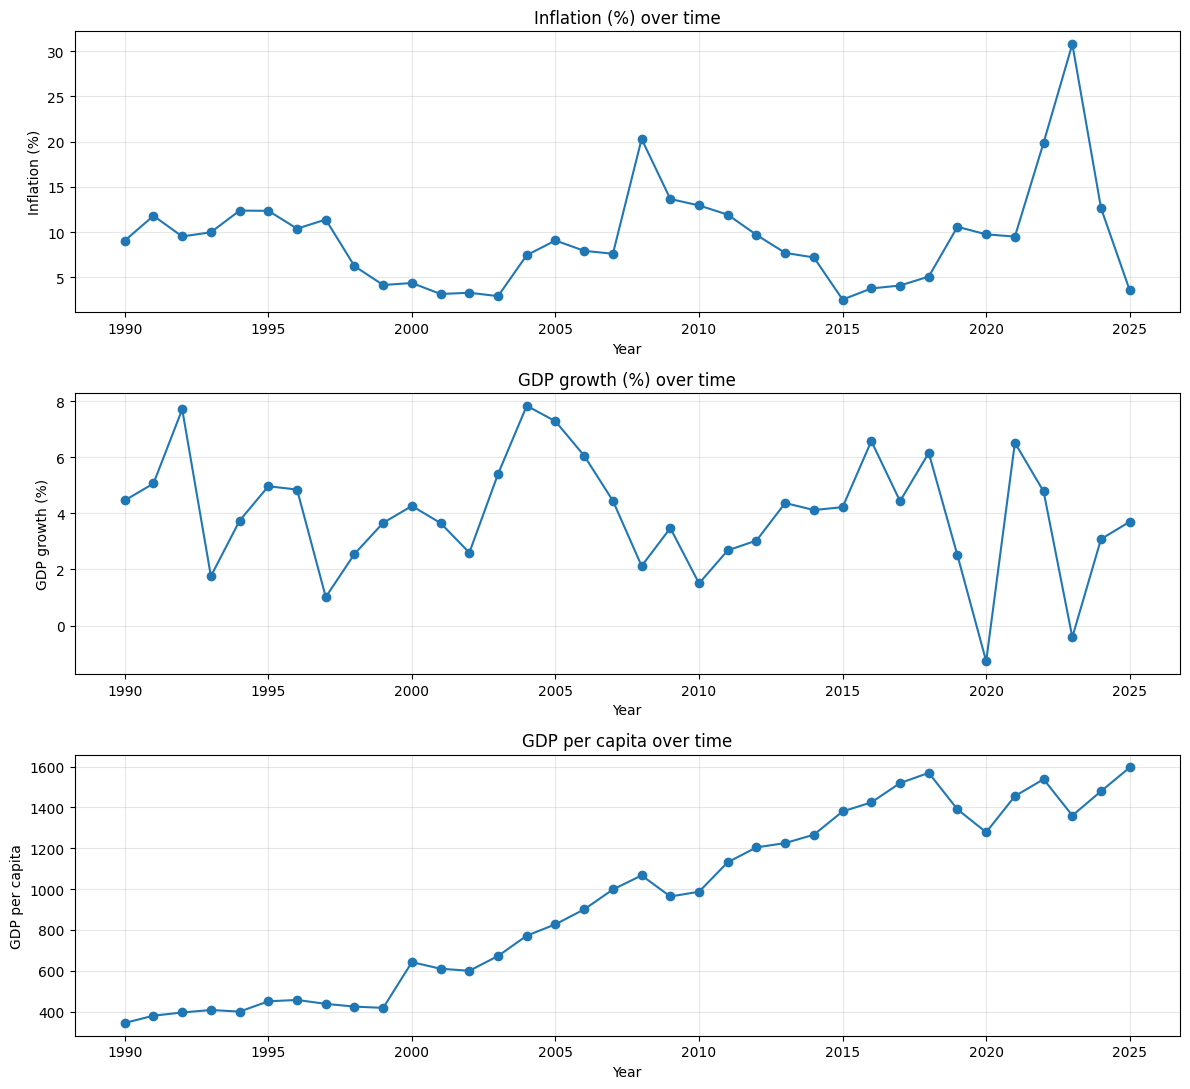

,1990–2007 mean,2008–2025 mean
Inflation,7.94,10.86
GDP Growth,4.51,3.42
GDP Per Capita,563.30,1324.34


In [ ]:

fig, axes = plt.subplots(3, 1, figsize=(12, 11))

series = [
    ("Inflation", "Inflation (%)"),
    ("GDP Growth", "GDP growth (%)"),
    ("GDP Per Capita", "GDP per capita")
]

for ax, (col, label) in zip(axes, series):
    ax.plot(df["Years"], df[col], marker="o")
    ax.set_title(f"{label} over time")
    ax.set_xlabel("Year")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

early = df[df["Years"].between(1990, 2007)]
recent = df[df["Years"].between(2008, 2025)]

comparison = pd.DataFrame({
    "1990–2007 mean": early[
        ["Inflation", "GDP Growth", "GDP Per Capita"]
    ].mean(),
    "2008–2025 mean": recent[
        ["Inflation", "GDP Growth", "GDP Per Capita"]
    ].mean()
})

display(comparison.round(2))
